# Blocco 1: Caricamento del dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sys

Si importa il dataset su cui effettuare il machine learning

In [2]:
from ucimlrepo import fetch_ucirepo

dataset = fetch_ucirepo(id=17)

X = dataset.data.features
y = dataset.data.targets

In [3]:
print(X.shape)
print(y.shape)

(569, 30)
(569, 1)


Il numero 569 si riferisce al numero di pazienti (numero di campioni).
Il numero 30 si riferisce al numero di colonne che si hanno.
Il numero 1 si riferisce alle diagnosi che si hanno.

## Esplorazione dei dati

Si mostrano le 5 righe di una tabella

In [4]:
X.head()

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [5]:
y.head()

,Diagnosis
0,M
1,M
2,M
3,M
4,M


Si mostra un riassunto della tabella: si possono vedere il nome e il tipo di ogni colonna, possiamo vedere se ci sono valori mancanti e il tipo di dato che ne è contenuto.

In [6]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   radius1             569 non-null    float64
 1   texture1            569 non-null    float64
 2   perimeter1          569 non-null    float64
 3   area1               569 non-null    float64
 4   smoothness1         569 non-null    float64
 5   compactness1        569 non-null    float64
 6   concavity1          569 non-null    float64
 7   concave_points1     569 non-null    float64
 8   symmetry1           569 non-null    float64
 9   fractal_dimension1  569 non-null    float64
 10  radius2             569 non-null    float64
 11  texture2            569 non-null    float64
 12  perimeter2          569 non-null    float64
 13  area2               569 non-null    float64
 14  smoothness2         569 non-null    float64
 15  compactness2        569 non-null    float64
 16  concavity2         

Si calcola la media, la deviazione standard, il minimo, il massimo e i quartili di ogni colonna.

In [7]:
X.describe()

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


Si verifica se ci sono valori mancanti

In [8]:
X.isnull().sum()

radius1               0
texture1              0
perimeter1            0
area1                 0
smoothness1           0
compactness1          0
concavity1            0
concave_points1       0
symmetry1             0
fractal_dimension1    0
radius2               0
texture2              0
perimeter2            0
area2                 0
smoothness2           0
compactness2          0
concavity2            0
concave_points2       0
symmetry2             0
fractal_dimension2    0
radius3               0
texture3              0
perimeter3            0
area3                 0
smoothness3           0
compactness3          0
concavity3            0
concave_points3       0
symmetry3             0
fractal_dimension3    0
dtype: int64

Si verifica la distribuzione delle classi

In [9]:
y.columns

Index(['Diagnosis'], dtype='str')

Diagnosis
B            357
M            212
Name: count, dtype: int64


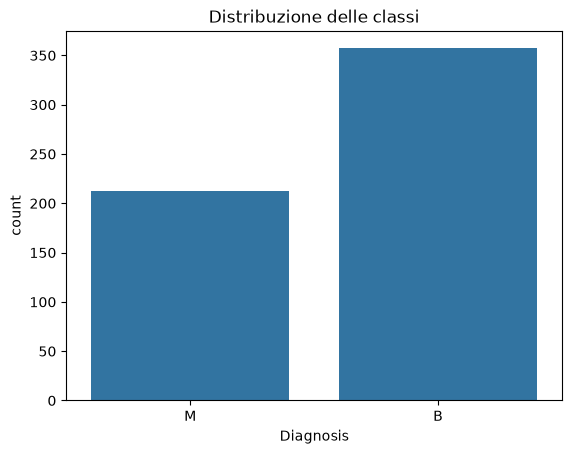

In [10]:
print(y.value_counts())

sns.countplot(x=y['Diagnosis'])
plt.title("Distribuzione delle classi")
plt.savefig("distribuzione_classi.png", dpi=200, bbox_inches="tight")
plt.show()

Da questa prima analisi si può dire che:

1) **Non ci sono valori mancanti**: non serve eliminare righe né riempire valori vuoti.

2) **Le classi sono moderatamente sbilanciate**: si hanno 357 benigni (62,7%) e 212 maligni (37,3%). Un modello che prevede sempre "benigno" avrebbe circa il 63% di accuracy senza riconoscere nessun tumore maligno, ragion per cui l'accuracy da sola non basta e si devono tenere in considerazione anche precision, recall, F1 e ROC AUC (in ambito medico soprattutto la recall sui maligni). Inoltre lo split dei dati deve essere **stratificato**, in modo che training, validation e test mantengano le stesse proporzioni di benigni e maligni.

3) **Le feature hanno scale molto diverse.** Si prendano ad esempio due feature, area1 e smoothness1:
   - media di area1 ≈ 655;
   - media di smoothness1 ≈ 0,096.

   Se i dati non fossero standardizzati, KNN, che calcola le distanze sommando le differenze tra le feature, non risentirebbe quasi per niente della smoothness: le differenze di area sono di centinaia, quelle di smoothness di pochi centesimi. Lo stesso vale per la PCA, che cerca le direzioni di massima varianza e verrebbe dominata dalle feature con numeri grandi. Per questo bisognerà **standardizzare** i dati.

# Blocco 2: Analisi con la PCA

Si standardizzano i dati per la PCA

In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler_pca = StandardScaler()
X_std = scaler_pca.fit_transform(X)

Si calcola la PCA

In [12]:
pca = PCA()
X_pca = pca.fit_transform(X_std)

print (pca.explained_variance_ratio_)

[4.42720256e-01 1.89711820e-01 9.39316326e-02 6.60213492e-02
 5.49576849e-02 4.02452204e-02 2.25073371e-02 1.58872380e-02
 1.38964937e-02 1.16897819e-02 9.79718988e-03 8.70537901e-03
 8.04524987e-03 5.23365745e-03 3.13783217e-03 2.66209337e-03
 1.97996793e-03 1.75395945e-03 1.64925306e-03 1.03864675e-03
 9.99096464e-04 9.14646751e-04 8.11361259e-04 6.01833567e-04
 5.16042379e-04 2.72587995e-04 2.30015463e-04 5.29779290e-05
 2.49601032e-05 4.43482743e-06]


Possiamo notare come le prime componenti contengano **gran parte dell'informazione**: ogni componente successiva spiega una quota più piccola della precedente. Sommando le prime quattro componenti si ottiene 44,27% + 18,97% + 9,39% + 6,60% = 79,23% dell'informazione. Questo accade perché **molte feature sono correlate tra loro** (ad esempio raggio, perimetro e area del nucleo crescono insieme): la PCA concentra queste informazioni ripetute in poche componenti.

PC1 e PC2 da sole spiegano il 63,3% dell'informazione: un grafico con solo queste due componenti mostra buona parte della struttura dei dati, ma non tutta.

Si va a vedere quante componenti servono per arrivare al 95%

In [13]:
import numpy as np

varianza_cumulata = np.cumsum(pca.explained_variance_ratio_)
n_95 = np.argmax(varianza_cumulata >= 0.95) + 1

print("Varianza cumulata:", varianza_cumulata.round(3))
print("Componenti per il 95%:", n_95)

Varianza cumulata: [0.443 0.632 0.726 0.792 0.847 0.888 0.91  0.926 0.94  0.952 0.961 0.97
 0.978 0.983 0.986 0.989 0.991 0.993 0.995 0.996 0.997 0.997 0.998 0.999
 0.999 1.    1.    1.    1.    1.   ]
Componenti per il 95%: 10


Questo ci fa capire che per arrivare al 95% ci servono solo 10 componenti su 30. Teoricamente potremmo dire che riducendo i dati **ad un terzo** si perderebbe solo il 5% delle informazioni.

Per l'addestramento dei modelli si utilizzeranno le 30 feature originali (standardizzate), **non le componenti principali**, per tre motivi:
- **interpretabilità:** le feature originali hanno un significato reale ("il raggio del nucleo è grande" è comprensibile per un medico, mentre "**PC3** è alta" non vuol dire niente);
- **la riduzione non serve:** 30 feature sono poche e i modelli si addestrano velocemente anche così; ridurre le dimensioni è utile quando le feature sono migliaia;
- **lo scopo della PCA nel progetto:** la usiamo solo come strumento di analisi e visualizzazione dei dati.

Andiamo ad analizzare e a disegnare la curva dei numeri che abbiamo stampato, in modo da vedere dove la curva supera la soglia.

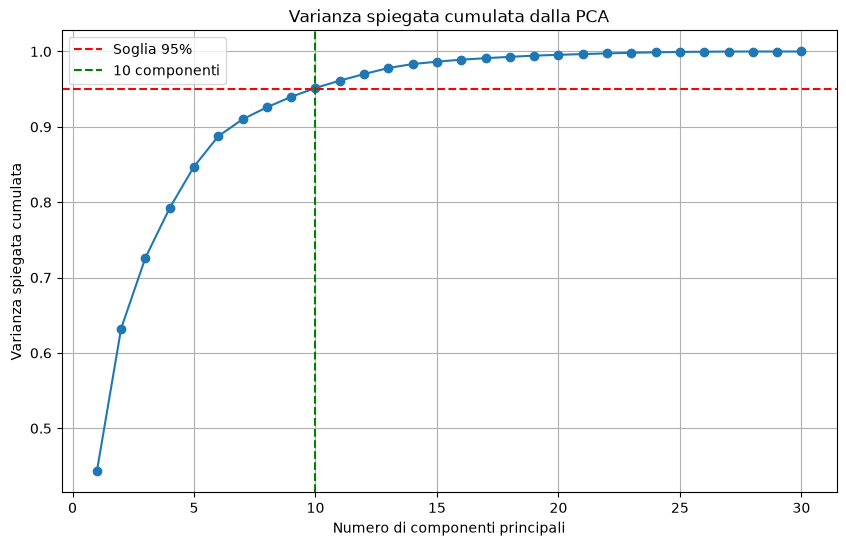

In [14]:
plt.figure(figsize=(10,6))
plt.plot(range(1,31), varianza_cumulata, marker='o')
plt.axhline(y=0.95, color='r', linestyle='--', label='Soglia 95%')
plt.axvline(x=n_95, color='g', linestyle='--', label=f'{n_95} componenti')
plt.xlabel('Numero di componenti principali')
plt.ylabel('Varianza spiegata cumulata')
plt.title('Varianza spiegata cumulata dalla PCA')
plt.legend()
plt.grid(True)
plt.savefig('pca_varianza_cumulata.png', dpi=200, bbox_inches='tight')
plt.show()

Rappresentiamo ora ogni paziente con un punto, usando la PC1 come coordinata orizzontale e PC2 come coordinata verticale, coloriamo in base alla diagnosi. Andiamo quindi a controllare che maligni e benigni si trovino in due zone diverse del grafico (buon segno).

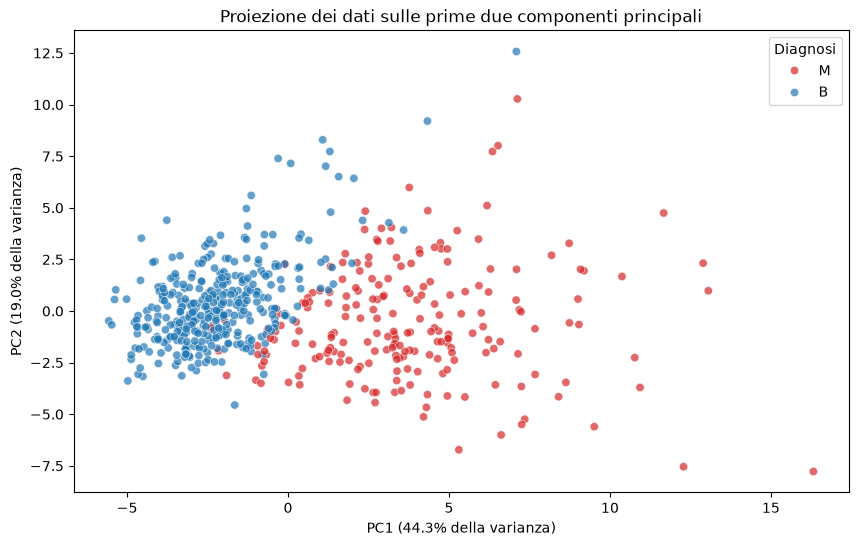

In [15]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y['Diagnosis'],
                palette={'B': 'tab:blue', 'M': 'tab:red'}, alpha=0.7)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} della varianza)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} della varianza)')
plt.title('Proiezione dei dati sulle prime due componenti principali')
plt.legend(title='Diagnosi')
plt.savefig('pca_scatter_pc1_pc2.png', dpi=200, bbox_inches='tight')
plt.show()

Le due classi si separano bene con una sovrapposizione minima. Bisogna andare a vedere bene la classificazione tra maligno e benigno sulla zona di accumulo dei punti (dove è più probabile si trovino gli errori dei modelli). Le classi si distinguono soprattutto in orizzontale, ovvero lungo la PC1 (che è la componente con più varianza). Dobbiamo però fare una precisazione. Noi stiamo vedendo il grafico in due dimensioni, la sovrapposizione delle classi potrebbe non esserci nel momento in cui si passa ad una visualizzazione più ampia.

# Blocco 3: Suddivisione dei dati e standardizzazione

Si divide il **dataset** in tre parti, con uno split **stratificato** (ogni parte mantiene circa il 63% di benigni e il 37% di maligni) e `random_state=42` per rendere la divisione riproducibile:
- **training (60%, 341 pazienti):** per addestrare i modelli;
- **validation (20%, 114 pazienti):** per confrontare i modelli e scegliere i parametri (ad esempio il k del KNN e l'architettura della rete);
- **test (20%, 114 pazienti):** per **stimare le prestazioni finali su pazienti mai visti**.

Il test viene usato **una sola volta, alla fine**: poiché sul validation si sono prese delle decisioni, i suoi risultati sono leggermente ottimisti; il test, mai utilizzato prima, fornisce invece una stima onesta. Se dopo averlo visto si modificassero i modelli, perderebbe questo valore.

Per prima cosa si divide il test dal resto del dataset.

In [16]:
from sklearn.model_selection import train_test_split

## la funzione restituisce 4 pezzi: 
## feature del primo gruppo, feature del secondo gruppo, target del primo gruppo e target del secondo gruppo
## stratify=y lo split è stratificat: ogni gruppo mantiene la proporzione 63% benigni e 37% maligni
## random_state=42 fissa il seme del caso, la divisione è casuale.
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42)

print("Training:    ", X_train.shape)
print("Validation:  ", X_val.shape)
print("Test:        ", X_test.shape)

Training:     (341, 30)
Validation:   (114, 30)
Test:         (114, 30)


La media e la deviazione standard si calcolano solo sul training, per poi applicarle sul validation e il test. Questo per fare in modo che le informazioni facente parte del validation e del test non entri a far parte del training. Questo porterebbe un problema di Data Leakage, la valutazione sembrerebbe migliore di quanto è davvero.

Utilizziamo sul training la fit_transform -> impara media e deviazione standard e trasforma i dati

Utilizziamo sul validation e sul test la transform -> applica le medie già imparate senza ricalcolarle

In [17]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Media training (prime 3 feature): ", X_train_scaled.mean(axis=0)[:3].round(3))
print("Media validation (prime 3 feature): ", X_val_scaled.mean(axis=0)[:3].round(3))

Media training (prime 3 feature):  [ 0. -0.  0.]
Media validation (prime 3 feature):  [ 0.003 -0.01   0.007]


Prepariamo il target.

I classificatori scikit-learn vogliono le feature X strutturate come una tabella e il target come una fila, poichè un paziente ha una singola etichetta.

In [18]:
y_train_arr = y_train.values.ravel()
y_val_arr = y_val.values.ravel()
y_test_arr = y_test.values.ravel()

# Blocco 4: I classificatori

 ## **_Naive Bayes_**

Il Naive Bayes utilizza il **teorema di Bayes**: per ogni paziente si calcola la probabilità che il tumore **sia** maligno o benigno, dati i valori delle feature, e si sceglie la classe più probabile.

Il modello è detto **"naive" (ingenuo)** perché ipotizza che **le feature siano indipendenti tra loro, data la classe**. Nel nostro caso questa ipotesi non è vera: ad esempio raggio, perimetro e area sono feature **strettamente** legate tra loro (come visto anche con la PCA). Nonostante questo, il modello ottiene buoni risultati, come spesso accade nella pratica.

La **versione gaussiana** (`GaussianNB`) assume che ogni feature, all'interno di ciascuna classe, abbia una **distribuzione** gaussiana (a campana): è la versione **adatta** al nostro caso, perché le feature sono numeriche continue.

In [19]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
## ADDESTRAMENTO: per ogni classe e ogni feature calcola media e varianza sui 341 pazienti di training
nb.fit(X_train_scaled, y_train_arr) 

## Fa prevedere al modello la diagnosi dei 114 paziendi di validation e calcola l'accuracy
acc_nb = nb.score(X_val_scaled, y_val_arr)
## Arrotonda a 3 decimali
print("Naive Bayes - accuracy sul validation:", round(acc_nb, 3))

Naive Bayes - accuracy sul validation: 0.956


In [20]:
baseline = (y_val_arr == 'B').mean()
print("Accuracy del modello che dice sempre 'benigno':", round(baseline, 3))

Accuracy del modello che dice sempre 'benigno': 0.623


L'accuracy è la percentuale di risposte giuste. Un accuracy che ci si aspetta in un modello "stupido" è quello uguale alla percentuale della classe più frequente (nel nostro caso il 62,3% sul validation). Il Naive Bayes presenta invece un accuracy del 95.6%, questo ne consegue che è un buon classificatore, in quanto ha imparato a distinguere i tumori. 

## **_KNN: K-Nearest Neighbors_**

Il KNN è un classificatore che si basa sui k più vicini. In pratica si calcola la distanza tra lui e tutti i 341 pazienti del training, si prendono i k pazienti più vicini, si guarda la loro diagnosi e vince la maggioranza.

Il KNN non impara davvero tramite il fit, ma si limita a memorizzare i pazienti di training, infatti il lavoro vero e proprio si fa al momento della previsione; per questo è definito "pigro". Inoltre, la standardizzazione diventa fondamentale.

Il k **si sceglie dispari**: avendo due classi, un numero dispari di vicini evita i **pareggi** nel voto (ad esempio, con k=4 potrebbero esserci 2 vicini benigni e 2 maligni).

Il valore di k determina il compromesso tra overfitting e underfitting:
- **k piccolo** (ad esempio k=1, si guarda un solo vicino): rischio di **overfitting**, perché basta un singolo paziente "anomalo" nel training per sbagliare la previsione;
- **k grande**: il **voto a maggioranza** coinvolge anche pazienti lontani e poco simili, i confini tra le classi diventano troppo grossolani e si **rischia l'underfitting**.

Per scegliere k si confronta l'accuracy sul validation per k = 1, 3, 5, ..., 21.

k =  1  ->  accuracy = 0.947
k =  3  ->  accuracy = 0.965
k =  5  ->  accuracy = 0.974
k =  7  ->  accuracy = 0.974
k =  9  ->  accuracy = 0.974
k = 11  ->  accuracy = 0.974
k = 13  ->  accuracy = 0.974
k = 15  ->  accuracy = 0.974
k = 17  ->  accuracy = 0.974
k = 19  ->  accuracy = 0.974
k = 21  ->  accuracy = 0.965


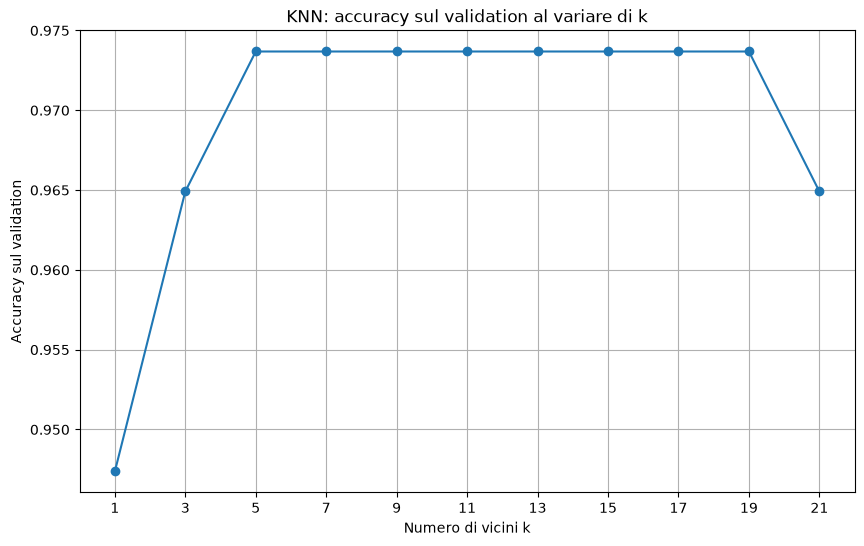

In [21]:
from sklearn.neighbors import KNeighborsClassifier

valori_k = range(1, 22, 2)
accuracy_k = []

for k in valori_k:
    modello = KNeighborsClassifier(n_neighbors=k)
    modello.fit(X_train_scaled, y_train_arr)
    accuracy_k.append(modello.score(X_val_scaled, y_val_arr))

for k, acc in zip(valori_k, accuracy_k):
    print(f"k = {k:2d}  ->  accuracy = {acc:.3f}")

plt.figure(figsize=(10, 6))
plt.plot(valori_k, accuracy_k, marker='o')
plt.xlabel('Numero di vicini k')
plt.ylabel('Accuracy sul validation')
plt.title('KNN: accuracy sul validation al variare di k')
plt.xticks(valori_k)
plt.grid(True)
plt.savefig('knn_scelta_k.png', dpi=200, bbox_inches='tight')
plt.show()

Si sceglie k=5, ovvero il valore più piccolo che raggiunge l’accuracy massima sul validation (0,974). Per k tra 5 e 19 l’accuracy resta invariata, quindi la scelta non è critica; k=1 risulta peggiore, coerente con il rischio di overfitting di un solo vicino.

In [22]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train_arr)

acc_knn = knn.score(X_val_scaled, y_val_arr)
print("KNN (k=5) - accuracy sul validation:", round(acc_knn, 3))

KNN (k=5) - accuracy sul validation: 0.974


## **_Random forest_**

L'**albero decisionale** è una serie di domande **sì/no** sulle feature, simile a un diagramma di flusso. Durante l'addestramento si sceglie quali domande fare e con quali soglie, in modo da distinguere al meglio i tumori maligni da quelli benigni. **Un singolo albero, però, tende all'overfitting: impara troppo nel dettaglio i pazienti di training.**

La **foresta** è un insieme di tanti alberi decisionali (nel nostro caso **100**), resi diversi tra loro in due modi:
- ogni albero si addestra su un **campione casuale** dei pazienti di training, estratto **con ripetizione** (**bootstrap**);
- a ogni domanda, ogni albero può scegliere solo tra un **sottoinsieme casuale di feature**.

Per classificare un paziente ogni albero vota e vince la maggioranza. **Poiché gli alberi sono diversi, i loro errori tendono a compensarsi e la foresta generalizza meglio di un singolo albero.** La combinazione di più modelli si chiama **ensemble**.

In [23]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_scaled, y_train_arr)

acc_rf = rf.score(X_val_scaled, y_val_arr)
print("Random Forest - accuracy sul validation:", round(acc_rf, 3))

Random Forest - accuracy sul validation: 0.974


**Nota:** la Random Forest **non ha bisogno della standardizzazione**. Un albero fa domande su una feature alla volta: se si cambia la scala (ad esempio passando da cm a mm), l'albero sposta semplicemente la soglia ("raggio > 15 cm" diventa "raggio > 150 mm") e divide i pazienti allo stesso modo. Le feature non vengono mai sommate né confrontate tra loro, quindi la loro scala non conta. **Al contrario, KNN calcola distanze sommando le differenze di tutte le feature, e per questo la standardizzazione è indispensabile.**

Abbiamo comunque fornito alla Random Forest i dati standardizzati **per uniformità**: tutti i modelli ricevono gli stessi dati, ed è più semplice. Per la Random Forest la standardizzazione non è necessaria, ma nemmeno dannosa.

# Blocco 5: Le matrici di confusione

## Valutazione sul validation

La matrice di confusione va a contare i pazienti nei quattro casi possibili. Gli stati della matrice si ricorda sono **TN** (True Negative - vero negativo), **FN** (False Negative - falso negativo), **FP** (False Positive - falso positivo), **TP** (True Positive - vero positivo) 

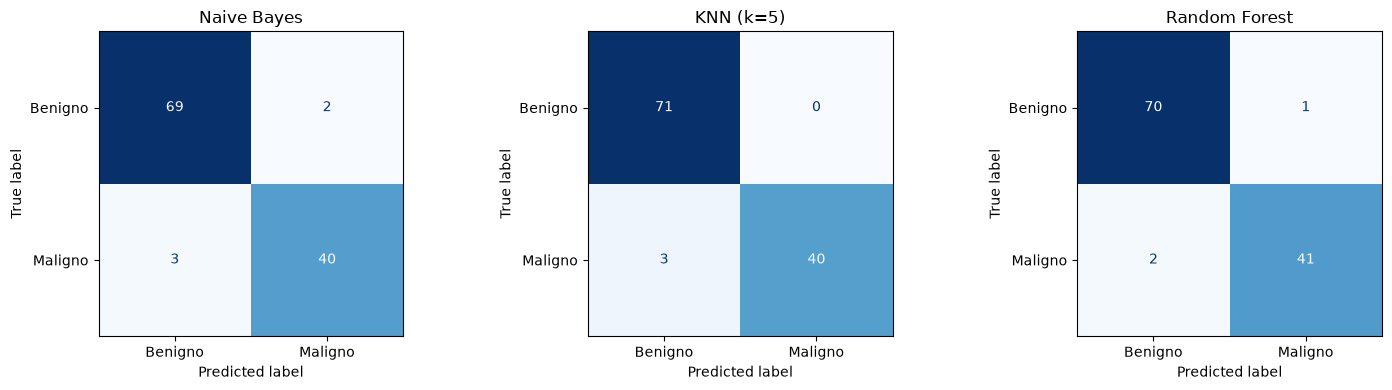

In [24]:
from sklearn.metrics import ConfusionMatrixDisplay

modelli = {"Naive Bayes": nb, "KNN (k=5)": knn, "Random Forest": rf}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nome, modello) in zip(axes, modelli.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_val_arr, modello.predict(X_val_scaled),
        labels=['B', 'M'], display_labels=['Benigno', 'Maligno'],
        cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(nome)
    ax.grid(False)
plt.tight_layout()
plt.savefig('confusion_matrix_validation.png', dpi=200, bbox_inches='tight')
plt.show()

L'errore più grave è il **falso negativo (FN)**: un tumore **maligno** che il modello classifica come **benigno**. In questo caso il paziente non verrebbe curato.

Il **falso positivo (FP)**, cioè un tumore benigno classificato come maligno, è meno grave: porta a esami di approfondimento e preoccupazione inutili, ma alla fine il paziente sta bene.

Per questo, nel confronto tra i modelli, diamo particolare importanza al numero di falsi negativi e quindi alla **recall** sulla classe maligna.

I tre modelli commettono pochi errori (da 3 a 5 su 114). KNN non produce falsi positivi, mentre Random Forest ha il minor numero di falsi negativi; dato che in ambito medico un tumore non individuato è l’errore più grave, Random Forest risulta leggermente preferibile, anche se la differenza è di un solo paziente e non permette di stabilire un vincitore netto.

## Le metriche

- **ACCURACY**: (TP+TN)/totale -> numero di risposte giuste in tutto.
- **PRECISION**: TP/(TP+FP) -> quando il modello dice "maligno" quante volte ha ragione. 
- **RECALL**: TP/(TP+FN) -> Dei tumori maligni veri, quanti ne trova? 
- **F1-SCORE**: 2PR/(P+R) -> Una media "equilibrata" di precision e recall.
- **ROC AUC**: area sotto la curva ROC -> Quanto bene il modello separa le due classi? 0,5 = a caso, 1 = perfetto

In [25]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

POS = 'M'

def calcola_metriche(modello, X_dati, y_veri):
    y_pred = modello.predict(X_dati)
    idx_pos = list(modello.classes_).index(POS)
    y_prob = modello.predict_proba(X_dati)[:, idx_pos]
    return {
        "Accuracy": accuracy_score(y_veri, y_pred),
        "Precision": precision_score(y_veri, y_pred, pos_label=POS),
        "Recall": recall_score(y_veri, y_pred, pos_label=POS),
        "F1-score": f1_score(y_veri, y_pred, pos_label=POS),
        "ROC AUC": roc_auc_score(y_veri == POS, y_prob),
    }

risultati_val = pd.DataFrame(
    {nome: calcola_metriche(m, X_val_scaled, y_val_arr) for nome, m in modelli.items()}
).T
risultati_val.round(3)

,Accuracy,Precision,Recall,F1-score,ROC AUC
Naive Bayes,0.956,0.952,0.930,0.941,0.990
KNN (k=5),0.974,1.000,0.930,0.964,0.995
Random Forest,0.974,0.976,0.953,0.965,0.991


KNN e Random Forest hanno la stessa accuracy (0,974), ma si differenziano nel modo in cui sbagliano. La **recall** della Random Forest è 0,953 (41 tumori maligni individuati su 43), mentre quella di Naive Bayes e KNN è 0,930 (40 su 43): la differenza corrisponde a **un solo tumore** in più individuato. Il KNN, invece, ha **precision** pari a 1,000, perché non produce alcun falso allarme.

Poiché in ambito medico un tumore non individuato è l'errore più grave, la recall è la metrica più rilevante; tuttavia, con 43 tumori maligni nel validation, ogni tumore vale circa 2,3 punti di recall, e differenze così piccole non permettono di stabilire un modello migliore.

## Le curve ROC

La curva ROC mostra il compromesso tra tumori individuati (TPR) e falsi allarmi (FPR) al variare della soglia di decisione; l’AUC riassume la curva in un numero, pari alla probabilità che il modello assegni a un paziente maligno una probabilità più alta che a un benigno

Il modello va a calcolare le probabilità di un tumore di essere maligno. Per trasformare la probabilità in una risposta serve una soglia. Per ogni soglia si contano la **TPR (True Positive Rate)** - recall - e la **FPR (False Positive Rate)** - quota di falsi allarmi.  

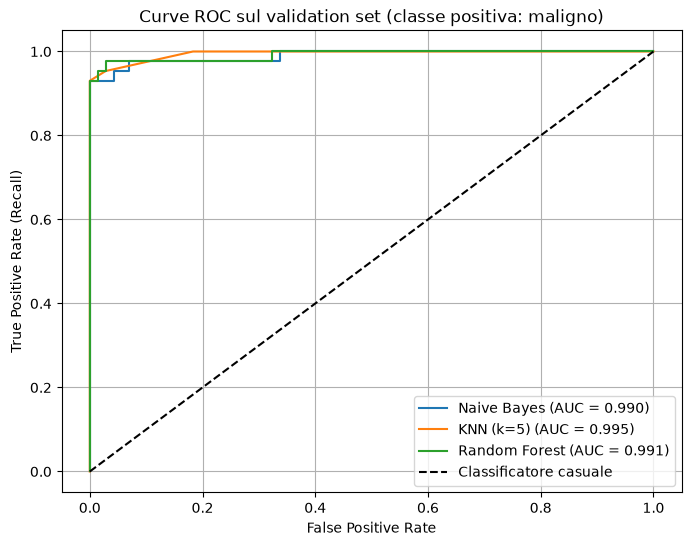

In [26]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(8, 6))
for nome, modello in modelli.items():
    idx_pos = list(modello.classes_).index(POS)
    y_prob = modello.predict_proba(X_val_scaled)[:, idx_pos]
    fpr, tpr, soglie = roc_curve(y_val_arr == POS, y_prob)
    auc = roc_auc_score(y_val_arr == POS, y_prob)
    plt.plot(fpr, tpr, label=f"{nome} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label="Classificatore casuale")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("Curve ROC sul validation set (classe positiva: maligno)")
plt.legend(loc="lower right")
plt.grid(True)
plt.savefig("roc_validation.png", dpi=200, bbox_inches="tight")
plt.show()

Dal grafico si vede che le curve dei tre modelli salgono quasi lungo l'asse verticale e poi proseguono lungo il bordo superiore. Restano quindi vicine all'angolo in alto a sinistra (TPR = 1, FPR = 0: tutti i tumori individuati senza falsi allarmi) e molto lontane dalla diagonale, che rappresenta un classificatore casuale (AUC = 0,5).

Gli AUC sono tutti molto alti: 0,990 per Naive Bayes, 0,995 per KNN e 0,991 per Random Forest. Tutti e tre i modelli riescono quindi a distinguere quasi perfettamente i tumori benigni da quelli maligni, come ci si poteva aspettare dallo scatter della PCA, dove le due classi apparivano già ben separate.

Non si può però indicare un modello migliore. Le differenze di AUC sono molto piccole (al massimo 0,005) e, con 114 pazienti di validation, potrebbero cambiare con una suddivisione diversa dei dati. Inoltre KNN ha l'AUC più alta, mentre Random Forest ha la recall migliore: le due metriche misurano cose diverse, perché la recall dipende dalla soglia di 0,5, mentre l'AUC valuta il modello su tutte le soglie possibili.

# Blocco 6: Deep learning: rete neurale MLP

MLP sta per Multi-Layer Perceptron, cioè rete neurale a più strati. È fatta di neuroni organizzati in strati (layer):

```
 30 feature        strato nascosto 1    strato nascosto 2      uscita
 (input)           (es. 32 neuroni)     (es. 16 neuroni)     (1 neurone)

  raggio  ──┐
  texture ──┼──►  ○ ○ ○ ... ○  ──►   ○ ○ ... ○  ──►   ○  → probabilità di "maligno"
  ...     ──┤
  area    ──┘
```

Un neurone prende i valori in ingresso, moltiplica ciascuno di essi per un peso, li somma, aggiunge un bias e passa il risultato a una funzione di attivazione.

Gli strati in una MLP sono:
- **Strati nascosti (hidden layer)**: si usa l'attivazione ReLU, che vale 0 se il numero è negativo e lascia il numero così come è se è positivo. Questo per rendere la rete non lineare: senza funzioni di attivazione non lineari, più strati equivarrebbero a un unico strato lineare.
- **Strato di uscita**: composto da un solo neurone con attivazione sigmoide, che trasforma qualsiasi numero in un valore tra 0 e 1.

La MLP impara nel seguente modo:

1. la rete fa una previsione
2. una funzione di loss misura quanto ha sbagliato. Per la classificazione binaria si utilizza la binary cross-entropy
3. la backpropagation calcola come modificare ogni peso per ridurre l'errore
4. Si ottimizza (nel caso in questione tramite Adam) aggiornando i pesi
5. si ripete il tutto per molte **epoche** (1 epoca = la rete ha visto tutti i pazienti di training esattamente una volta)

Non si è scelta una CNN in quanto queste vengono utilizzate per immagini. Neanche la RNN risultava efficace poichè nel caso del dataset Breast Cancer Wisconsin non si tratta di dati sequenziali (come testi o serie temporali).

## Preparazione dei dati

A differenza di scikit-learn la rete neurale vuole numeri e non lettere. Nel caso in questione l'etichetta 'M' si associa al numero binario 1, mentre l'etichetta 'B' si associa allo 0. Inoltre vi è il concetto di riproducibilità. Quindi, la rete parte da **pesi casuali** ma il seme viene fissato, ogni volta che si rilancia quindi si ottiene lo stesso identico risultato.

In [27]:
## si importa la libreria per il deep learning
import tensorflow as tf
## Keras è la parte di TensorFlow con cui si costruiscono delle reti neurali semplici
from tensorflow import keras

## si fissa il seme
tf.keras.utils.set_random_seed(42)

## per ogni paziente si produrrà True in caso di maligno o False in caso di Benigno
y_train_nn = (y_train_arr == 'M').astype(int)
y_val_nn = (y_val_arr == 'M').astype(int)
y_test_nn = (y_test_arr == 'M').astype(int)

print("TensorFlow:", tf.__version__)
print("Prime 10 etichette originali:", y_train_arr[:10])
print("Prime 10 etichette per la rete:", y_train_nn[:10])

2026-11-15 14:06:14.255764: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow: 2.16.2
Prime 10 etichette originali: ['M' 'B' 'B' 'B' 'B' 'B' 'B' 'M' 'B' 'M']
Prime 10 etichette per la rete: [1 0 0 0 0 0 0 1 0 1]


## Costruzione della rete

### Architettura della rete (rete A)

La rete è costruita con una funzione, `crea_rete(neuroni_1, neuroni_2, dropout)`,
in modo da poter provare architetture diverse cambiando solo tre numeri.

| Strato | Neuroni | Attivazione | Ruolo |
|---|---|---|---|
| Input | 30 | – | una feature standardizzata per neurone |
| Dense (nascosto 1) | 32 | ReLU | ogni neurone è collegato a tutti i 30 ingressi |
| Dropout | – | – | spegne a caso il 30% dei neuroni a ogni passo di training |
| Dense (nascosto 2) | 16 | ReLU | secondo livello di elaborazione |
| Dense (uscita) | 1 | sigmoide | restituisce la probabilità che il tumore sia maligno (tra 0 e 1) |

**Perché ReLU negli strati nascosti:** vale 0 per input negativi e lascia invariati
quelli positivi; introduce la non linearità, senza la quale più strati equivarrebbero a uno solo.

**Perché la sigmoide in uscita:** schiaccia qualsiasi valore tra 0 e 1, quindi
l'uscita si può leggere come probabilità della classe "maligno".

**Perché il dropout:** impedisce alla rete di dipendere da pochi neuroni e di
memorizzare il training → riduce l'overfitting. È attivo solo durante l'addestramento;
in previsione lavorano tutti i neuroni.

### Compilazione: come impara la rete

- **Loss = binary cross-entropy** → misura l'errore nei problemi a due classi;
  punisce soprattutto gli errori fatti "con sicurezza" (es. 0,99 di maligno per un benigno).
- **Ottimizzatore = Adam** → variante della discesa del gradiente che regola
  da sola il passo di aggiornamento per ciascun peso.
- **Metrica = accuracy** → stampata a ogni epoca per seguire l'addestramento.

In [28]:
def crea_rete(neuroni_1, neuroni_2, dropout):
    modello = keras.Sequential([
        keras.Input(shape=(30,)),
        keras.layers.Dense(neuroni_1, activation='relu'),
        keras.layers.Dropout(dropout),
        keras.layers.Dense(neuroni_2, activation='relu'),
        keras.layers.Dense(1, activation='sigmoid'),
    ])
    modello.compile(optimizer='adam',
                    loss='binary_crossentropy',
                    metrics=['accuracy'])
    return modello

tf.keras.utils.set_random_seed(42)
rete_A = crea_rete(32, 16, 0.3)
rete_A.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,537 (6.00 KB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

## Addestrare la rete A

In [29]:
## si controlla la loss sul validation dopo ogni epoca
## patience = 20 sta ad indicare che se dopo 20 epoche di fila la loss non migliora, si ferma
## restore_best_weights=True alla fine si rimettono i pesi migliori e non quelli dell'ultima epoca
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=20, restore_best_weights=True)

## validation_data -> si calcola per ogni epoca la loss e l'accuracy anche sul validation
## epochs=300 -> indica il numero massimo di epoche
## batch_size=16 -> i pesi si aggiornano ogni 16 pazienti
storia_A = rete_A.fit(
    X_train_scaled, y_train_nn,
    validation_data=(X_val_scaled, y_val_nn),
    epochs=300, batch_size=16,
    callbacks=[early_stop], verbose=0)

## si riporta la epoca migliore con la loss di validation più bassa
epoca_migliore_A = np.argmin(storia_A.history['val_loss']) + 1
print("Epoche eseguite:", len(storia_A.history['loss']))
print("Epoca migliore:", epoca_migliore_A)
print("Loss minima sul validation:", round(min(storia_A.history['val_loss']), 4))

Epoche eseguite: 44
Epoca migliore: 24
Loss minima sul validation: 0.0696


## Le curve di apprendimento

Si rappresentano ora loss e accuracy epoca per epoca su training e validation.

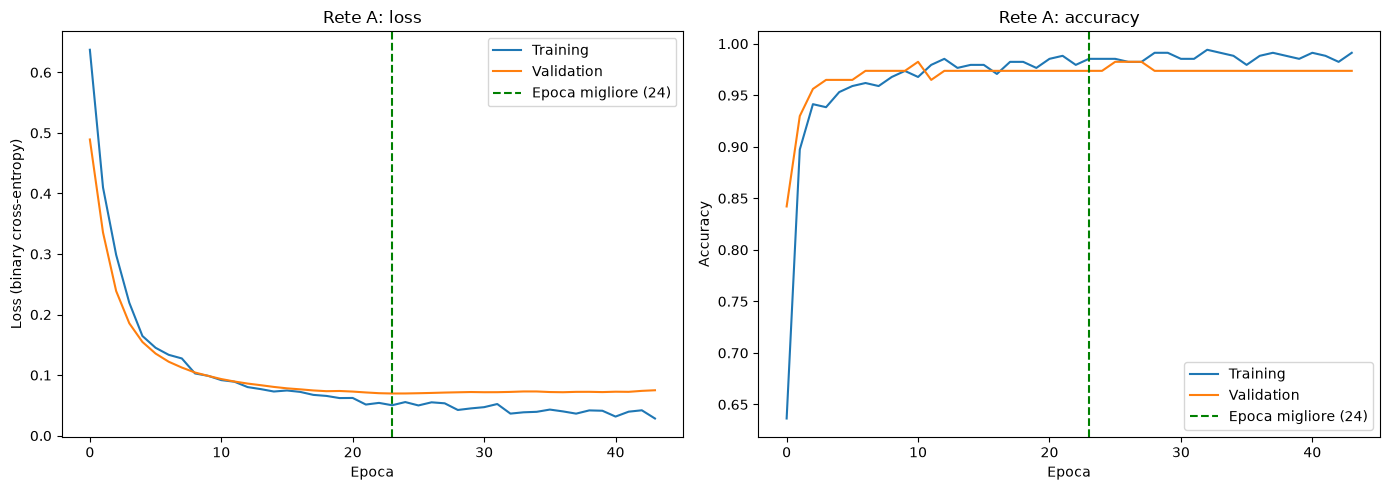

In [30]:
## si impostano due grafici affiancati, a sinistra la loss e a destra l'accuracy
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

## LOSS
axes[0].plot(storia_A.history['loss'], label='Training')
axes[0].plot(storia_A.history['val_loss'], label='Validation')
## si inserisce una linea verticale verde sull'epoca migliore
axes[0].axvline(x=epoca_migliore_A - 1, color='g', linestyle='--',
                label=f'Epoca migliore ({epoca_migliore_A})')
axes[0].set_xlabel('Epoca')
axes[0].set_ylabel('Loss (binary cross-entropy)')
axes[0].set_title('Rete A: loss')
axes[0].legend()

## ACCURACY
axes[1].plot(storia_A.history['accuracy'], label='Training')
axes[1].plot(storia_A.history['val_accuracy'], label='Validation')
## si inserisce una linea verticale verde sull'epoca migliore
axes[1].axvline(x=epoca_migliore_A - 1, color='g', linestyle='--',
                label=f'Epoca migliore ({epoca_migliore_A})')
axes[1].set_xlabel('Epoca')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Rete A: accuracy')
axes[1].legend()

plt.tight_layout()
plt.savefig('mlp_A_curve_apprendimento.png', dpi=200, bbox_inches='tight')
plt.show()

Nel grafico della **loss** si può notare come entrambe le curve scendano rapidamente nelle prime epoche. Dall'epoca 24 la loss di training continua a scendere leggermente, mentre quella di validation si appiattisce per poi salire leggermente: è il segnale dell’inizio dell’overfitting. L’early stopping (patience 20) ha interrotto l’addestramento all’epoca 44 e ripristinato i pesi dell’epoca 24, quella con la minore loss di validation.

L'**accuracy** sale molto velocemente nelle prime epoche. Dall'epoca 24 l'accuracy del training continua ad oscillare tra 1 e 0.95 mentre quella di validation si appiattisce.

## Rete B

In [31]:
tf.keras.utils.set_random_seed(42)
rete_B = crea_rete(16, 8, 0.2)
rete_B.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

In [32]:
early_stop_B = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=20, restore_best_weights=True)

storia_B = rete_B.fit(
    X_train_scaled, y_train_nn,
    validation_data=(X_val_scaled, y_val_nn),
    epochs=300, batch_size=16,
    callbacks=[early_stop_B], verbose=0)

epoca_migliore_B = np.argmin(storia_B.history['val_loss']) + 1

for nome, rete, epoca in [("Rete A", rete_A, epoca_migliore_A),
                          ("Rete B", rete_B, epoca_migliore_B)]:
    loss_val, acc_val = rete.evaluate(X_val_scaled, y_val_nn, verbose=0)
    print(f"{nome}: parametri = {rete.count_params()}, epoca migliore = {epoca}, "
          f"loss val = {loss_val:.4f}, accuracy val = {acc_val:.3f}")

Rete A: parametri = 1537, epoca migliore = 24, loss val = 0.0696, accuracy val = 0.974
Rete B: parametri = 641, epoca migliore = 163, loss val = 0.1207, accuracy val = 0.974


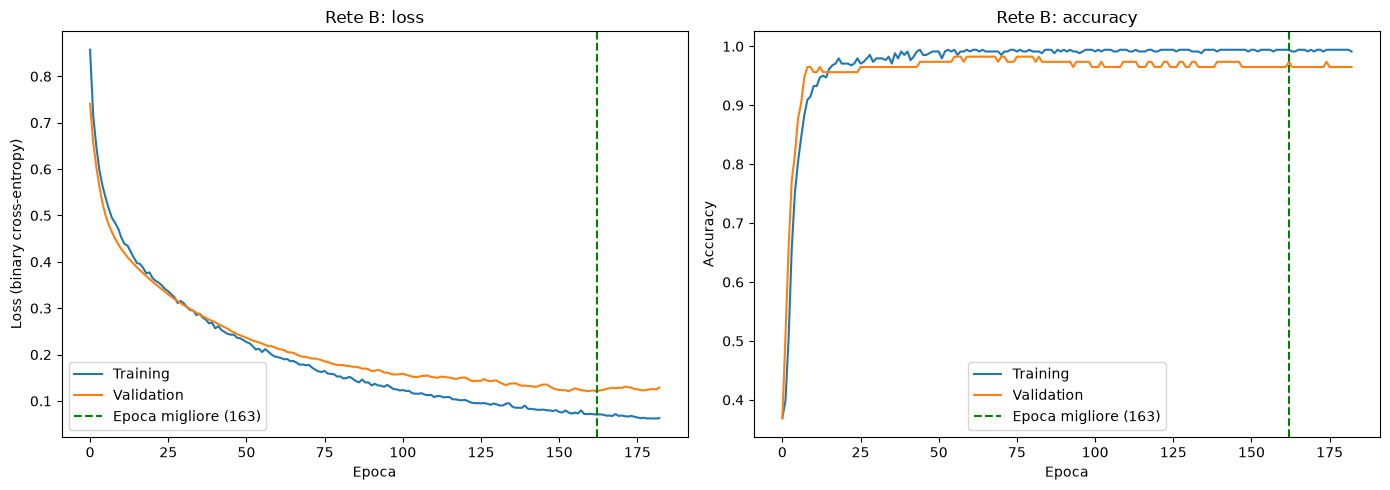

In [33]:
## si impostano due grafici affiancati, a sinistra la loss e a destra l'accuracy
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

## LOSS
axes[0].plot(storia_B.history['loss'], label='Training')
axes[0].plot(storia_B.history['val_loss'], label='Validation')
## si inserisce una linea verticale verde sull'epoca migliore
axes[0].axvline(x=epoca_migliore_B - 1, color='g', linestyle='--',
                label=f'Epoca migliore ({epoca_migliore_B})')
axes[0].set_xlabel('Epoca')
axes[0].set_ylabel('Loss (binary cross-entropy)')
axes[0].set_title('Rete B: loss')
axes[0].legend()

## ACCURACY
axes[1].plot(storia_B.history['accuracy'], label='Training')
axes[1].plot(storia_B.history['val_accuracy'], label='Validation')
## si inserisce una linea verticale verde sull'epoca migliore
axes[1].axvline(x=epoca_migliore_B - 1, color='g', linestyle='--',
                label=f'Epoca migliore ({epoca_migliore_B})')
axes[1].set_xlabel('Epoca')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Rete B: accuracy')
axes[1].legend()

plt.tight_layout()
plt.savefig('mlp_B_curve_apprendimento.png', dpi=200, bbox_inches='tight')
plt.show()

### Rete B: confronto con un'architettura più piccola

La rete B usa la stessa funzione `crea_rete` della rete A (stesse attivazioni,
stessa loss, stesso ottimizzatore, stesso early stopping). Cambiano solo le dimensioni:

| | Rete A | Rete B |
|---|---|---|
| Neuroni strato nascosto 1 | 32 | 16 |
| Neuroni strato nascosto 2 | 16 | 8 |
| Dropout | 0,3 | 0,2 |
| Parametri totali | 1.537 | 641 |

Il dataset di training contiene solo 341 pazienti. Si vuole verificare
se una rete con meno parametri, quindi meno incline all'overfitting, ottiene
risultati simili alla rete A.

**Risultati sul validation:**

| | Epoca migliore | Loss validation | Accuracy validation |
|---|---|---|---|
| Rete A | 24 | 0,0696 | 0,974 |
| Rete B | 163 | 0,1207 | 0,974 |

**Scelta:** I valori dell'accuracy sono identici, la loss validation è nettamente inferiore nella rete A, quasi della metà. Inoltre presenta una curva di apprendimento molto più veloce. Si preferisce la rete A.

### Valutazione della rete con le stesse metriche dei modelli shallow

**Obiettivo:** confrontare la rete A con Naive Bayes, KNN e Random Forest usando
esattamente gli stessi strumenti: la funzione `calcola_metriche`, le matrici di
confusione e le curve ROC. Così il confronto è alla pari.

**Il problema:** la rete Keras non funziona come un modello di scikit-learn.

| | Modelli scikit-learn | Rete Keras |
|---|---|---|
| `predict` | restituisce l'etichetta, `'B'` o `'M'` | restituisce la probabilità di "maligno" (es. 0,93) |
| `predict_proba` | due colonne: probabilità di B e di M | non esiste |
| `classes_` | l'elenco delle classi, `['B', 'M']` | non esiste |

**La soluzione: un adattatore.** È stata scritta una piccola classe, `ReteKeras`, che
contiene la rete e la fa comportare come un modello di scikit-learn:

- `classes_` → contiene `['B', 'M']`, nello stesso ordine degli altri modelli;
- `predict_proba(X)` → prende la probabilità di "maligno" p calcolata dalla rete
  e restituisce due colonne: 1 − p (benigno) e p (maligno);
- `predict(X)` → trasforma la probabilità in etichetta con soglia 0,5:
  `'M'` se p ≥ 0,5, altrimenti `'B'`.

La rete dentro l'adattatore non cambia: cambia solo il modo in cui le si chiedono
le previsioni.

**Infine** si aggiunge la rete al dizionario `modelli`, che ora contiene quattro
modelli, e si ricalcola la tabella delle metriche sul validation per tutti e quattro.

In [34]:
## Definisce lo stampo
class ReteKeras:
    ## metodo che salva la rete dentro l'oggetto
    def __init__(self, rete):
        self.rete = rete
        ## si crea l'elenco delle classi
        self.classes_ = np.array(['B', 'M'])

    def predict_proba(self, X):
        ## si richiedono le probabilità di maligno alla rete
        p_maligno = self.rete.predict(X, verbose=0).ravel()
        ## si costruiscon due colonne: Prob benigno | Prob maligno
        return np.column_stack([1 - p_maligno, p_maligno])

    def predict(self, X):
        p_maligno = self.predict_proba(X)[:, 1]
        ## si trasforma la probabilità in etichetta con soglia 0.5
        return np.where(p_maligno >= 0.5, 'M', 'B')

## si crea l'adattatre attorno alla rete A
mlp = ReteKeras(rete_A)
## si aggiunge la rete al dizionario dei modelli
modelli["MLP (rete A)"] = mlp

risultati_val = pd.DataFrame(
    {nome: calcola_metriche(m, X_val_scaled, y_val_arr) for nome, m in modelli.items()}
).T
risultati_val.round(3)

,Accuracy,Precision,Recall,F1-score,ROC AUC
Naive Bayes,0.956,0.952,0.930,0.941,0.990
KNN (k=5),0.974,1.000,0.930,0.964,0.995
Random Forest,0.974,0.976,0.953,0.965,0.991
MLP (rete A),0.974,0.976,0.953,0.965,0.996


### Matrici di confusione e ROC con la rete

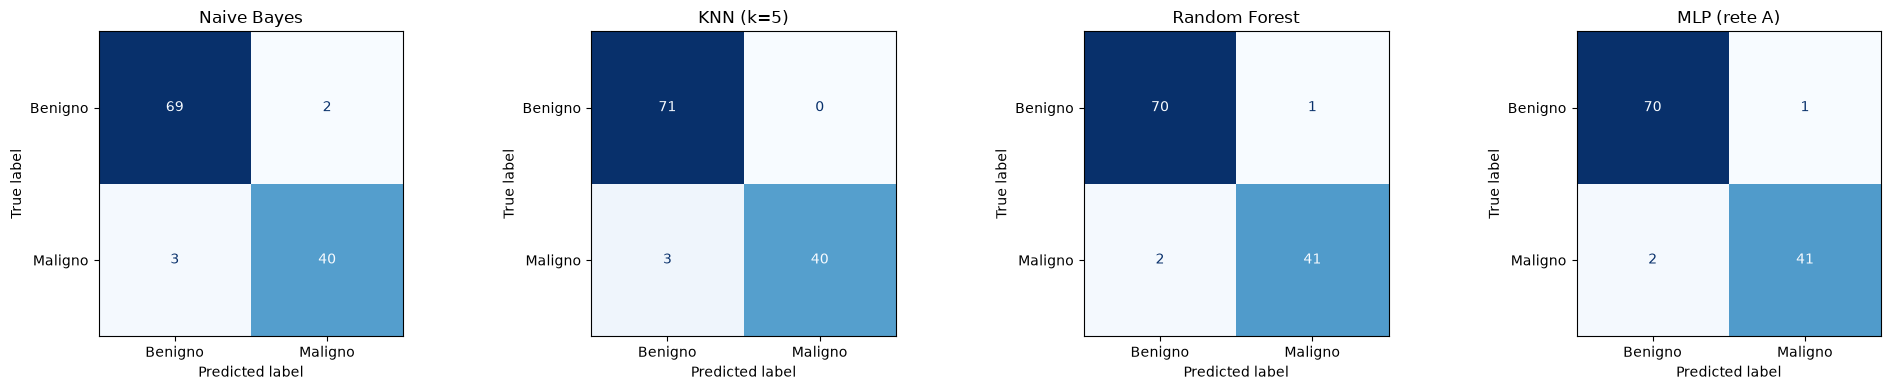

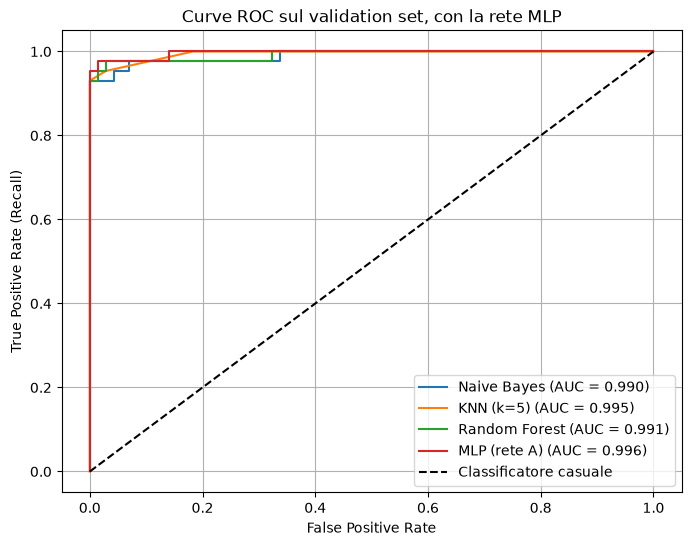

In [35]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (nome, modello) in zip(axes, modelli.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_val_arr, modello.predict(X_val_scaled),
        labels=['B', 'M'], display_labels=['Benigno', 'Maligno'],
        cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(nome)
    ax.grid(False)
plt.tight_layout()
plt.savefig('confusion_matrix_validation_con_mlp.png', dpi=200, bbox_inches='tight')
plt.show()

plt.figure(figsize=(8, 6))
for nome, modello in modelli.items():
    y_prob = modello.predict_proba(X_val_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_val_arr == POS, y_prob)
    auc = roc_auc_score(y_val_arr == POS, y_prob)
    plt.plot(fpr, tpr, label=f"{nome} (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], 'k--', label="Classificatore casuale")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("Curve ROC sul validation set, con la rete MLP")
plt.legend(loc="lower right")
plt.grid(True)
plt.savefig('roc_validation_con_mlp.png', dpi=200, bbox_inches='tight')
plt.show()

Sul validation la rete A ottiene esattamente le stesse metriche della Random Forest (accuracy 0,974, recall 0,953, un falso positivo e due falsi negativi) e l'AUC più alta dei quattro modelli (0,996), con una differenza però minima. La rete quindi **eguaglia i modelli shallow, ma non li supera**. È un risultato atteso: il deep learning dà il meglio con grandi quantità di dati e problemi complessi (come immagini o testi), mentre su un dataset tabellare piccolo (569 pazienti) e con classi già ben separabili anche modelli più semplici sono sufficienti.

# Blocco 7. Valutazione finale sul test set

### Metriche sul test

In [36]:
risultati_test = pd.DataFrame(
    {nome: calcola_metriche(m, X_test_scaled, y_test_arr) for nome, m in modelli.items()}
).T
risultati_test.round(3)

,Accuracy,Precision,Recall,F1-score,ROC AUC
Naive Bayes,0.921,0.923,0.857,0.889,0.990
KNN (k=5),0.947,0.974,0.881,0.925,0.982
Random Forest,0.956,0.974,0.905,0.938,0.998
MLP (rete A),0.982,1.000,0.952,0.976,0.996


### Matrici di confusione e ROC sul test

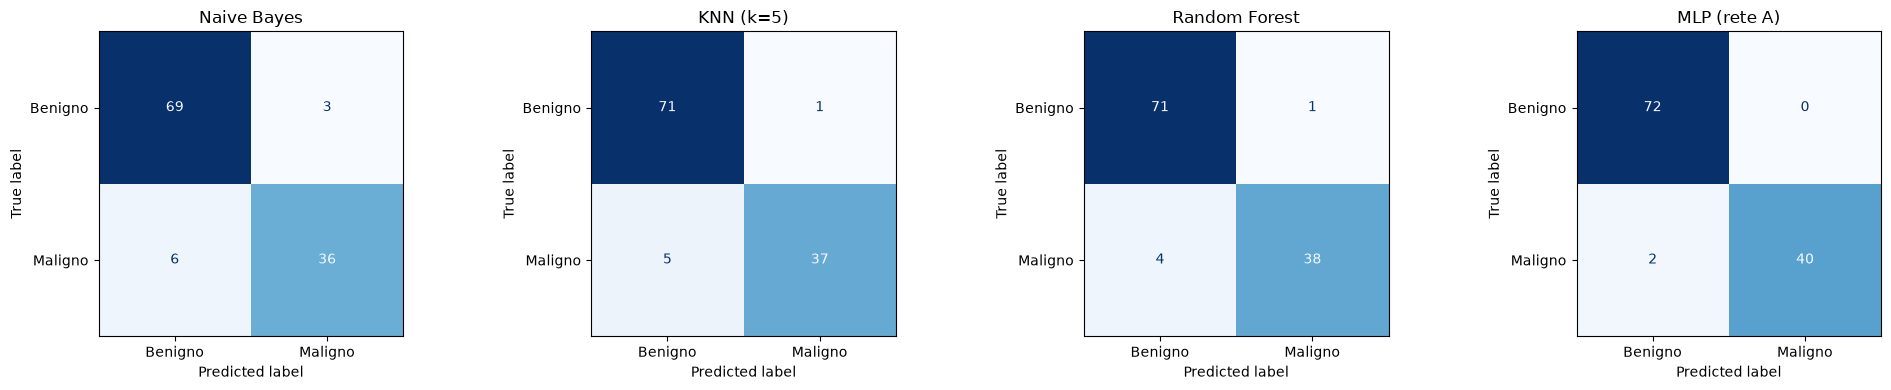

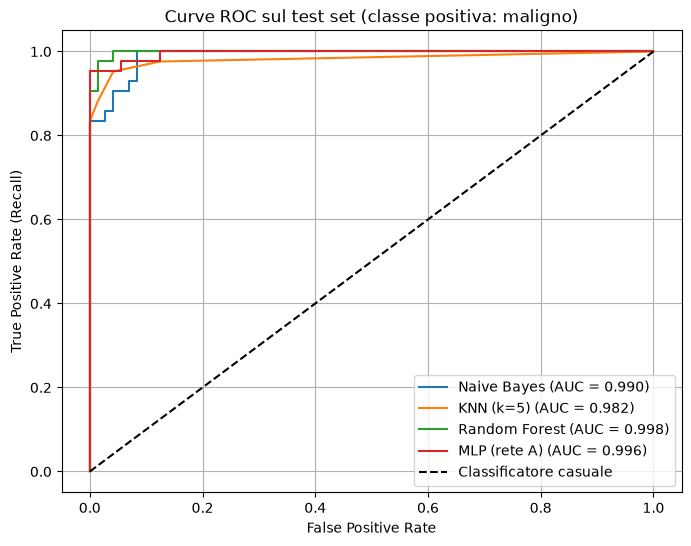

In [37]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (nome, modello) in zip(axes, modelli.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test_arr, modello.predict(X_test_scaled),
        labels=['B', 'M'], display_labels=['Benigno', 'Maligno'],
        cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(nome)
    ax.grid(False)
plt.tight_layout()
plt.savefig('confusion_matrix_test.png', dpi=200, bbox_inches='tight')
plt.show()

plt.figure(figsize=(8, 6))
for nome, modello in modelli.items():
    y_prob = modello.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test_arr == POS, y_prob)
    auc = roc_auc_score(y_test_arr == POS, y_prob)
    plt.plot(fpr, tpr, label=f"{nome} (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], 'k--', label="Classificatore casuale")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("Curve ROC sul test set (classe positiva: maligno)")
plt.legend(loc="lower right")
plt.grid(True)
plt.savefig('roc_test.png', dpi=200, bbox_inches='tight')
plt.show()

Il test **fornisce** una stima realistica delle prestazioni, **poiché non è mai stato utilizzato per prendere decisioni sui modelli**. In ambito medico la metrica più importante è la **recall**: i tumori mancati scendono da 6 nel Naive Bayes a 2 nella MLP.

Gli errori totali commessi da ciascun modello sono:
- Naive Bayes: 9;
- KNN: 6;
- Random Forest: 5;
- MLP: 2.

Rispetto al validation, i modelli shallow peggiorano sul test (ad esempio l'accuracy del Naive Bayes passa da 0,956 a 0,921, quella del KNN da 0,974 a 0,947). Si tratta di un comportamento atteso: sul validation sono stati scelti i parametri (come il k del KNN e l'architettura della rete), per cui i risultati ottenuti su di esso risultano leggermente ottimistici.

L'AUC più alta si osserva nella Random Forest (0,998). Se ne deduce che la Random Forest ordina molto bene i pazienti, ma con la soglia di 0,5 ne classifica in modo errato qualcuno in più.

Si nota inoltre che, sul validation, Random Forest e rete presentavano matrici di confusione identiche, mentre sul test la rete commette 3 errori in meno.

Si può quindi concludere che sul test la rete MLP ottiene i risultati migliori, sebbene la differenza tra i modelli sia di pochi pazienti. Poiché questi risultati derivano da un'unica suddivisione dei dati, con soli 114 pazienti di test, per una conclusione più solida sarebbe necessaria una validazione più robusta, come la K-fold cross validation, che ripete addestramento e valutazione su più suddivisioni diverse.